# Daftar Library Python

**Ruang Sampel dan Probabilitas Dasar: Dua Dadu**

n(S)                : 36
Kejadian jumlah = 7 : [(1, 6), (2, 5), (3, 4), (4, 3), (5, 2), (6, 1)]
P(jumlah=7) analitik: 1/6 = 0.1667
P(jumlah=7) simulasi: 0.1688
Selisih absolut     : 0.0022


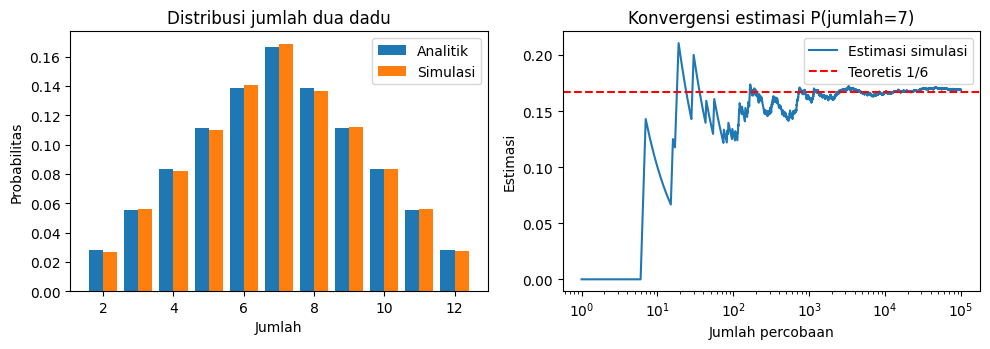

In [1]:
import itertools
from collections import Counter
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt

# --- Pendekatan analitik: enumerasi seluruh ruang sampel ---
ruang_sampel = list(itertools.product(range(1, 7), repeat=2))
jumlah_7 = [s for s in ruang_sampel if sum(s) == 7]
p_analitik = Fraction(len(jumlah_7), len(ruang_sampel))
print("n(S)                :", len(ruang_sampel))
print("Kejadian jumlah = 7 :", jumlah_7)
print("P(jumlah=7) analitik:", p_analitik, "=", round(float(p_analitik), 4))

# --- Simulasi Monte Carlo ---
rng = np.random.default_rng(42)
N = 100_000
d1 = rng.integers(1, 7, N)
d2 = rng.integers(1, 7, N)
jumlah = d1 + d2
hasil = (jumlah == 7)
print("P(jumlah=7) simulasi:", round(hasil.mean(), 4))
print("Selisih absolut     :", round(abs(hasil.mean() - float(p_analitik)), 4))

# --- Visualisasi ---
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
cnt = Counter(sum(s) for s in ruang_sampel)
x = np.arange(2, 13)
ax[0].bar(x - 0.2, [cnt[k] / 36 for k in x], 0.4, label="Analitik")
ax[0].bar(x + 0.2, [np.mean(jumlah == k) for k in x], 0.4, label="Simulasi")
ax[0].set(title="Distribusi jumlah dua dadu", xlabel="Jumlah", ylabel="Probabilitas")
ax[0].legend()
kum = np.cumsum(hasil) / np.arange(1, N + 1)
ax[1].semilogx(np.arange(1, N + 1), kum, label="Estimasi simulasi")
ax[1].axhline(1/6, color="red", ls="--", label="Teoretis 1/6")
ax[1].set(title="Konvergensi estimasi P(jumlah=7)", xlabel="Jumlah percobaan", ylabel="Estimasi")
ax[1].legend()
plt.tight_layout()
plt.savefig("P01_dadu.png", dpi=150)
plt.show()

**Kombinatorika: Permutasi dan Kombinasi**

In [3]:
import math, itertools
import numpy as np
from scipy.special import comb, perm

# (a) Probabilitas tim: tepat 2 frontend dari 4 anggota
mahasiswa = ["F"] * 4 + ["B"] * 6            # F = frontend, B = backend
p_rumus = comb(4, 2, exact=True) * comb(6, 2, exact=True) / comb(10, 4, exact=True)
print("C(4,2)*C(6,2)/C(10,4) =", round(p_rumus, 4))

# Verifikasi 1: enumerasi seluruh 210 tim yang mungkin
semua_tim = list(itertools.combinations(range(10), 4))
favorable = sum(1 for t in semua_tim if sum(mahasiswa[i] == "F" for i in t) == 2)
print("Enumerasi :", favorable, "/", len(semua_tim), "=", round(favorable / len(semua_tim), 4))

# Verifikasi 2: simulasi
rng = np.random.default_rng(1)
N = 100_000
hit = 0
for _ in range(N):
    t = rng.choice(10, 4, replace=False)
    hit += sum(mahasiswa[i] == "F" for i in t) == 2
print("Simulasi  :", round(hit / N, 4))

# (b) Menghitung banyaknya susunan
print("\nPassword 8 karakter (62^8)    :", f"{62**8:,}")
print("Susunan 5 jabatan dari 10 org  :", int(perm(10, 5)), "= P(10,5)")
print("Pilih 5 anggota dari 10 (tanpa urutan):", int(comb(10, 5)), "= C(10,5)")
print("Rasio P/C = 5! =", math.factorial(5))

C(4,2)*C(6,2)/C(10,4) = 0.4286
Enumerasi : 90 / 210 = 0.4286
Simulasi  : 0.4304

Password 8 karakter (62^8)    : 218,340,105,584,896
Susunan 5 jabatan dari 10 org  : 30240 = P(10,5)
Pilih 5 anggota dari 10 (tanpa urutan): 252 = C(10,5)
Rasio P/C = 5! = 120


**Probabilitas Bersyarat dan Independensi (Tabel Kontingensi)**

In [4]:
import pandas as pd
from scipy.stats import chi2_contingency

tabel = pd.DataFrame({"Lulus": [90, 40], "Tidak Lulus": [30, 40]},
                     index=["Python", "Java"])
total = tabel.values.sum()
print(tabel, "\nTotal =", total, "\n")

p_lulus  = tabel["Lulus"].sum() / total
p_python = tabel.loc["Python"].sum() / total
p_lulus_dan_python = tabel.loc["Python", "Lulus"] / total

p_lulus_given_python = p_lulus_dan_python / p_python
p_python_given_lulus = p_lulus_dan_python / p_lulus

print(f"P(Lulus)            = {p_lulus:.4f}")
print(f"P(Python)           = {p_python:.4f}")
print(f"P(Lulus ∩ Python)   = {p_lulus_dan_python:.4f}")
print(f"P(Lulus | Python)   = {p_lulus_given_python:.4f}")
print(f"P(Lulus | Java)     = {tabel.loc['Java','Lulus']/tabel.loc['Java'].sum():.4f}")
print(f"P(Python | Lulus)   = {p_python_given_lulus:.4f}")

# Uji independensi
print(f"\nP(Lulus)*P(Python)  = {p_lulus*p_python:.4f}  vs  P(Lulus∩Python) = {p_lulus_dan_python:.4f}")
chi2, p_value, dof, expected = chi2_contingency(tabel.values, correction=False)
print(f"Chi-kuadrat = {chi2:.3f}, dof = {dof}, p-value = {p_value:.4f}")
print("Kesimpulan:", "TIDAK bebas (dependen)" if p_value < 0.05 else "Tidak ada bukti ketergantungan")

        Lulus  Tidak Lulus
Python     90           30
Java       40           40 
Total = 200 

P(Lulus)            = 0.6500
P(Python)           = 0.6000
P(Lulus ∩ Python)   = 0.4500
P(Lulus | Python)   = 0.7500
P(Lulus | Java)     = 0.5000
P(Python | Lulus)   = 0.6923

P(Lulus)*P(Python)  = 0.3900  vs  P(Lulus∩Python) = 0.4500
Chi-kuadrat = 13.187, dof = 1, p-value = 0.0003
Kesimpulan: TIDAK bebas (dependen)


**Teorema Bayes: Filter Spam (Perhitungan Simbolik, Numerik, dan Simulasi)**

In [5]:
import sympy as sp
import numpy as np

# --- 1. Rumus simbolik ---
pS, pKS, pKH = sp.symbols("P_S P_K_S P_K_H", positive=True)
bayes = pKS * pS / (pKS * pS + pKH * (1 - pS))
print("Rumus simbolik   :", bayes)

nilai = {pS: sp.Rational(2, 5), pKS: sp.Rational(3, 5), pKH: sp.Rational(1, 20)}
hasil_exact = sp.nsimplify(bayes.subs(nilai))
print("Hasil eksak      :", hasil_exact, "=", float(hasil_exact))

# --- 2. Numerik langkah demi langkah ---
P_S, P_H = 0.4, 0.6
P_K_S, P_K_H = 0.6, 0.05
P_K = P_K_S * P_S + P_K_H * P_H
print(f"P(K) total       = {P_K:.4f}")
print(f"P(S|K) numerik   = {P_K_S * P_S / P_K:.4f}")

# --- 3. Simulasi 1.000.000 email ---
rng = np.random.default_rng(7)
N = 1_000_000
spam = rng.random(N) < P_S
kata = np.where(spam, rng.random(N) < P_K_S, rng.random(N) < P_K_H)
print(f"P(S|K) simulasi  = {spam[kata].mean():.4f}  (dari {kata.sum():,} email berkata 'gratis')")

Rumus simbolik   : P_K_S*P_S/(P_K_H*(1 - P_S) + P_K_S*P_S)
Hasil eksak      : 8/9 = 0.8888888888888888
P(K) total       = 0.2700
P(S|K) numerik   = 0.8889
P(S|K) simulasi  = 0.8893  (dari 269,689 email berkata 'gratis')


**Probabilitas Total dan Bayes dengan Banyak Hipotesis: Load Balancer**

          prior  p_error  prior*error  posterior
Server A    0.5     0.01        0.005     0.2381
Server B    0.3     0.02        0.006     0.2857
Server C    0.2     0.05        0.010     0.4762

P(Error) = 0.0210
Jumlah posterior = 1.0

Simulasi P(Error) = 0.0209
Simulasi P(Server | Error) = [0.2372 0.2892 0.4735]


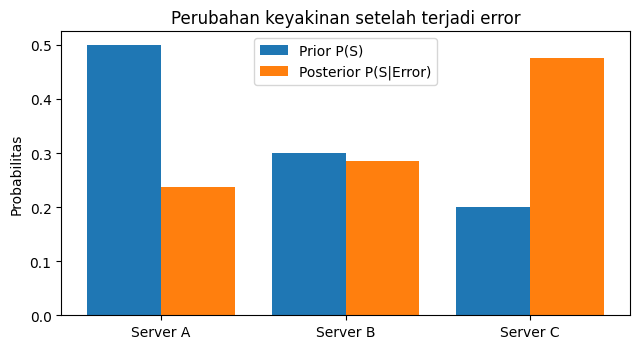

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.DataFrame({"prior": [0.50, 0.30, 0.20],
                   "p_error": [0.01, 0.02, 0.05]},
                  index=["Server A", "Server B", "Server C"])

df["prior*error"] = df["prior"] * df["p_error"]
P_error = df["prior*error"].sum()                 # probabilitas total
df["posterior"] = df["prior*error"] / P_error     # teorema Bayes
print(df.round(4))
print(f"\nP(Error) = {P_error:.4f}")
print("Jumlah posterior =", df["posterior"].sum().round(4))

# Verifikasi simulasi
rng = np.random.default_rng(3)
N = 2_000_000
server = rng.choice(3, N, p=df["prior"])
error = rng.random(N) < df["p_error"].values[server]
print(f"\nSimulasi P(Error) = {error.mean():.4f}")
print("Simulasi P(Server | Error) =", np.round(np.bincount(server[error]) / error.sum(), 4))

# Visualisasi prior vs posterior
x = np.arange(3)
plt.figure(figsize=(6.5, 3.6))
plt.bar(x - 0.2, df["prior"], 0.4, label="Prior P(S)")
plt.bar(x + 0.2, df["posterior"], 0.4, label="Posterior P(S|Error)")
plt.xticks(x, df.index); plt.ylabel("Probabilitas")
plt.title("Perubahan keyakinan setelah terjadi error")
plt.legend(); plt.tight_layout()
plt.savefig("P05_loadbalancer.png", dpi=150)
plt.show()

**Base Rate Fallacy: Deteksi Malware dan Pembaruan Bayes Berurutan**

Prior (prevalensi)          : 0.0100
Setelah 1x positif          : 0.1667
Setelah 2x positif berturut : 0.7984
Setelah 3x positif berturut : 0.9874
prevalensi  0.001 -> P(malware | +) = 0.0194
prevalensi  0.010 -> P(malware | +) = 0.1667
prevalensi  0.050 -> P(malware | +) = 0.5103
prevalensi  0.100 -> P(malware | +) = 0.6875
prevalensi  0.300 -> P(malware | +) = 0.8946
prevalensi  0.500 -> P(malware | +) = 0.9519

Simulasi P(malware | +) = 0.1662


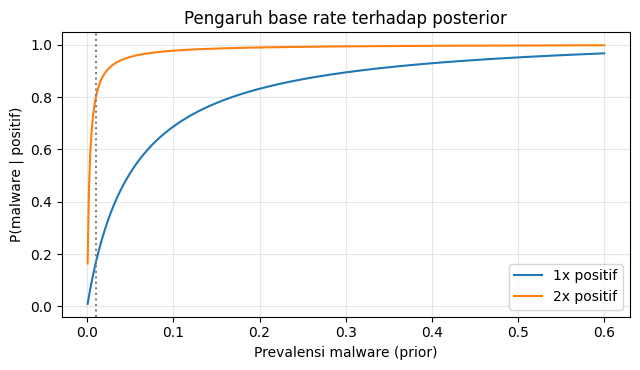

In [7]:
import numpy as np
import matplotlib.pyplot as plt

sens, fpr = 0.99, 0.05

def posterior(prior, sens=sens, fpr=fpr):
    """P(malware | hasil positif) dengan prior tertentu"""
    return sens * prior / (sens * prior + fpr * (1 - prior))

prior = 0.01
post1 = posterior(prior)
post2 = posterior(post1)           # posterior pertama dipakai sebagai prior kedua
post3 = posterior(post2)
print(f"Prior (prevalensi)          : {prior:.4f}")
print(f"Setelah 1x positif          : {post1:.4f}")
print(f"Setelah 2x positif berturut : {post2:.4f}")
print(f"Setelah 3x positif berturut : {post3:.4f}")

# Pengaruh prevalensi
for pr in [0.001, 0.01, 0.05, 0.10, 0.30, 0.50]:
    print(f"prevalensi {pr:6.3f} -> P(malware | +) = {posterior(pr):.4f}")

# Verifikasi simulasi untuk 1x positif
rng = np.random.default_rng(11)
N = 3_000_000
malware = rng.random(N) < prior
positif = np.where(malware, rng.random(N) < sens, rng.random(N) < fpr)
print(f"\nSimulasi P(malware | +) = {malware[positif].mean():.4f}")

# Grafik
pr = np.linspace(0.0005, 0.6, 400)
plt.figure(figsize=(6.5, 3.8))
plt.plot(pr, posterior(pr), label="1x positif")
plt.plot(pr, posterior(posterior(pr)), label="2x positif")
plt.axvline(0.01, color="gray", ls=":")
plt.xlabel("Prevalensi malware (prior)"); plt.ylabel("P(malware | positif)")
plt.title("Pengaruh base rate terhadap posterior"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig("P06_baserate.png", dpi=150); plt.show()

**Kombinasi Kejadian: Gabungan, Irisan, Komplemen, dan Inklusi-Eksklusi**

P(A), P(B), P(C)  : 0.5 0.4 0.3
P(A∩B)            : 0.2
P(A∩C)            : 0.0
P(B∩C)            : 0.1
P(A∩B∩C)          : 0.0

P(A∪B∪C) langsung        = 0.90
P(A∪B∪C) inklusi-eksklusi = 0.90
P(tidak memakai fitur)    = 0.10  (= 1 - P(A∪B∪C) = 0.10)
P(hanya Chat)             = 0.30
P(Chat atau Video, bukan Pembayaran) = 0.60


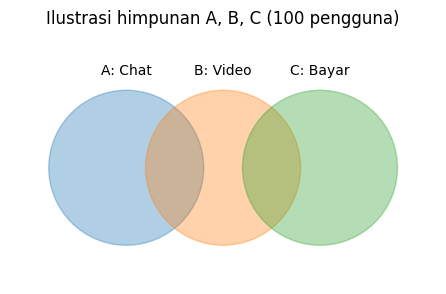

In [8]:
from itertools import combinations
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

U = set(range(100))
A, B, C = set(range(0, 50)), set(range(30, 70)), set(range(60, 90))
P = lambda s: len(s) / len(U)

print("P(A), P(B), P(C)  :", P(A), P(B), P(C))
print("P(A∩B)            :", P(A & B))
print("P(A∩C)            :", P(A & C))
print("P(B∩C)            :", P(B & C))
print("P(A∩B∩C)          :", P(A & B & C))

# Cara 1: langsung dengan operasi himpunan
p_union_langsung = P(A | B | C)

# Cara 2: rumus inklusi-eksklusi
S = [A, B, C]
p_ie = 0
for k in range(1, 4):
    tanda = (-1) ** (k + 1)
    for kombinasi in combinations(S, k):
        irisan = set.intersection(*kombinasi)
        p_ie += tanda * P(irisan)

print(f"\nP(A∪B∪C) langsung        = {p_union_langsung:.2f}")
print(f"P(A∪B∪C) inklusi-eksklusi = {p_ie:.2f}")
print(f"P(tidak memakai fitur)    = {P(U - (A | B | C)):.2f}  (= 1 - P(A∪B∪C) = {1 - p_ie:.2f})")
print(f"P(hanya Chat)             = {P(A - B - C):.2f}")
print(f"P(Chat atau Video, bukan Pembayaran) = {P((A | B) - C):.2f}")

# Diagram Venn sederhana
fig, ax = plt.subplots(figsize=(5.5, 3.6))
for (x, y), c, t in [((0.35, 0.5), "tab:blue", "A: Chat"), ((0.6, 0.5), "tab:orange", "B: Video"), ((0.85, 0.5), "tab:green", "C: Bayar")]:
    ax.add_patch(Circle((x, y), 0.2, color=c, alpha=0.35)); ax.text(x, y + 0.24, t, ha="center")
ax.set_xlim(0.05, 1.15); ax.set_ylim(0.2, 0.85); ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Ilustrasi himpunan A, B, C (100 pengguna)")
plt.savefig("P07_venn.png", dpi=150, bbox_inches="tight"); plt.show()

**Probabilitas Sistem: Keandalan Rangkaian Seri dan Paralel**

Keandalan blok DB (paralel) = 0.9600
Keandalan sistem            = 0.8208
Simulasi keandalan sistem   = 0.8202

Jumlah replika -> keandalan sistem
  1 replika -> 0.6840
  2 replika -> 0.8208
  3 replika -> 0.8482
  4 replika -> 0.8536
  5 replika -> 0.8547
  6 replika -> 0.8549


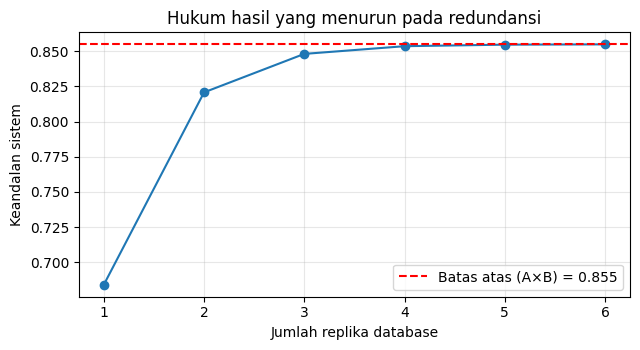

In [9]:
import numpy as np
import matplotlib.pyplot as plt

rA, rB, rC, rD = 0.95, 0.90, 0.80, 0.80

R_db = 1 - (1 - rC) * (1 - rD)          # paralel
R_sistem = rA * rB * R_db               # seri
print(f"Keandalan blok DB (paralel) = {R_db:.4f}")
print(f"Keandalan sistem            = {R_sistem:.4f}")

# Simulasi Monte Carlo
rng = np.random.default_rng(5)
N = 1_000_000
A = rng.random(N) < rA
B = rng.random(N) < rB
C = rng.random(N) < rC
D = rng.random(N) < rD
sistem_hidup = A & B & (C | D)
print(f"Simulasi keandalan sistem   = {sistem_hidup.mean():.4f}")

# Pengaruh jumlah replika database
print("\nJumlah replika -> keandalan sistem")
n_rep = np.arange(1, 7)
R_n = rA * rB * (1 - (1 - 0.80) ** n_rep)
for n, r in zip(n_rep, R_n):
    print(f"  {n} replika -> {r:.4f}")

plt.figure(figsize=(6.5, 3.6))
plt.plot(n_rep, R_n, "o-")
plt.axhline(rA * rB, color="red", ls="--", label="Batas atas (A×B) = 0.855")
plt.xlabel("Jumlah replika database"); plt.ylabel("Keandalan sistem")
plt.title("Hukum hasil yang menurun pada redundansi"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig("P08_reliabilitas.png", dpi=150); plt.show()

**Paradoks Ulang Tahun dan Tabrakan Hash**

n = 10 -> P(ada ulang tahun sama) = 0.1169
n = 20 -> P(ada ulang tahun sama) = 0.4114
n = 23 -> P(ada ulang tahun sama) = 0.5073
n = 30 -> P(ada ulang tahun sama) = 0.7063
n = 40 -> P(ada ulang tahun sama) = 0.8912
n = 57 -> P(ada ulang tahun sama) = 0.9901
n terkecil dengan P > 0.5 : 23
Simulasi n=23 (20000 percobaan): 0.5075

Ruang hash 32-bit M = 4,294,967,296
n untuk P(tabrakan) = 50%  ~ 77,163  (hanya 0.0018% dari M)
P(tabrakan) untuk n = 10.000 : 0.0116


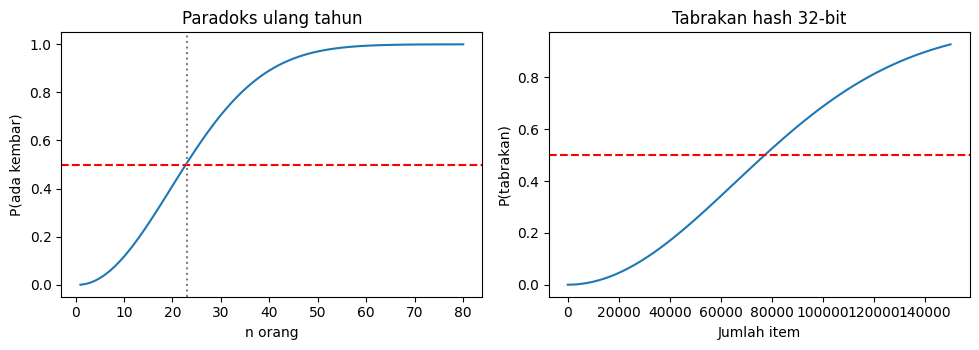

In [10]:
import numpy as np
import matplotlib.pyplot as plt

def p_kembar(n, hari=365):
    i = np.arange(n)
    return 1 - np.prod((hari - i) / hari)

for n in [10, 20, 23, 30, 40, 57]:
    print(f"n = {n:2d} -> P(ada ulang tahun sama) = {p_kembar(n):.4f}")

n_min = next(n for n in range(1, 366) if p_kembar(n) > 0.5)
print("n terkecil dengan P > 0.5 :", n_min)

# Simulasi untuk n = 23
rng = np.random.default_rng(2024)
trials = 20_000
hit = sum(len(set(rng.integers(0, 365, 23))) < 23 for _ in range(trials))
print(f"Simulasi n=23 ({trials} percobaan): {hit / trials:.4f}")

# (b) Tabrakan hash 32-bit
M = 2 ** 32
p_hash = lambda n: 1 - np.exp(-n * (n - 1) / (2 * M))
n50 = int(np.ceil(np.sqrt(2 * M * np.log(2))))
print(f"\nRuang hash 32-bit M = {M:,}")
print(f"n untuk P(tabrakan) = 50%  ~ {n50:,}  (hanya {n50 / M * 100:.4f}% dari M)")
print(f"P(tabrakan) untuk n = 10.000 : {p_hash(10_000):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ns = np.arange(1, 81)
ax[0].plot(ns, [p_kembar(n) for n in ns]); ax[0].axhline(0.5, color="r", ls="--")
ax[0].axvline(23, color="gray", ls=":"); ax[0].set(title="Paradoks ulang tahun", xlabel="n orang", ylabel="P(ada kembar)")
nh = np.linspace(1, 150_000, 300)
ax[1].plot(nh, p_hash(nh)); ax[1].axhline(0.5, color="r", ls="--")
ax[1].set(title="Tabrakan hash 32-bit", xlabel="Jumlah item", ylabel="P(tabrakan)")
plt.tight_layout(); plt.savefig("P09_birthday.png", dpi=150); plt.show()


**Simulasi Percobaan Acak: Masalah Monty Hall**

Analitik: P(menang | tetap) = 1/3 = 0.3333
Analitik: P(menang | pindah) = 2/3 = 0.6667

Simulasi (100,000 permainan)
  Tetap  : 0.3327
  Pindah : 0.6658


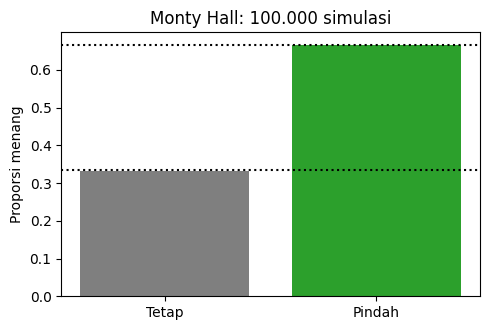

In [11]:
import random
import matplotlib.pyplot as plt

# --- Enumerasi: asumsikan hadiah di pintu 0, pemain memilih pintu 0/1/2 sama mungkin ---
menang_tetap = menang_pindah = 0
for pilihan in range(3):
    if pilihan == 0: menang_tetap += 1       # pilihan awal benar
    else:            menang_pindah += 1       # pilihan salah -> pindah pasti benar
print(f"Analitik: P(menang | tetap) = {menang_tetap}/3 = {menang_tetap/3:.4f}")
print(f"Analitik: P(menang | pindah) = {menang_pindah}/3 = {menang_pindah/3:.4f}")

# --- Simulasi ---
def main(pindah):
    hadiah = random.randrange(3)
    pilihan = random.randrange(3)
    dibuka = random.choice([p for p in range(3) if p != pilihan and p != hadiah])
    if pindah:
        pilihan = next(p for p in range(3) if p != pilihan and p != dibuka)
    return pilihan == hadiah

random.seed(123)
N = 100_000
tetap  = sum(main(False) for _ in range(N)) / N
pindah = sum(main(True)  for _ in range(N)) / N
print(f"\nSimulasi ({N:,} permainan)")
print(f"  Tetap  : {tetap:.4f}")
print(f"  Pindah : {pindah:.4f}")

plt.figure(figsize=(5, 3.4))
plt.bar(["Tetap", "Pindah"], [tetap, pindah], color=["tab:gray", "tab:green"])
plt.axhline(1/3, ls=":", color="k"); plt.axhline(2/3, ls=":", color="k")
plt.ylabel("Proporsi menang"); plt.title("Monty Hall: 100.000 simulasi")
plt.tight_layout(); plt.savefig("P10_montyhall.png", dpi=150); plt.show()

**Rantai Markov: Status Server dari Waktu ke Waktu**

Setelah  1 jam: {'Up': 0.9, 'Degraded': 0.08, 'Down': 0.02}
Setelah  2 jam: {'Up': 0.844, 'Degraded': 0.112, 'Down': 0.044}
Setelah  5 jam: {'Up': 0.7952, 'Degraded': 0.1276, 'Down': 0.0772}
Setelah 20 jam: {'Up': 0.7911, 'Degraded': 0.1266, 'Down': 0.0823}

Distribusi stasioner: {'Up': 0.7911, 'Degraded': 0.1266, 'Down': 0.0823}
Cek pi·P = pi        : True
Simulasi proporsi    : {'Up': 0.7917, 'Degraded': 0.1258, 'Down': 0.0825}


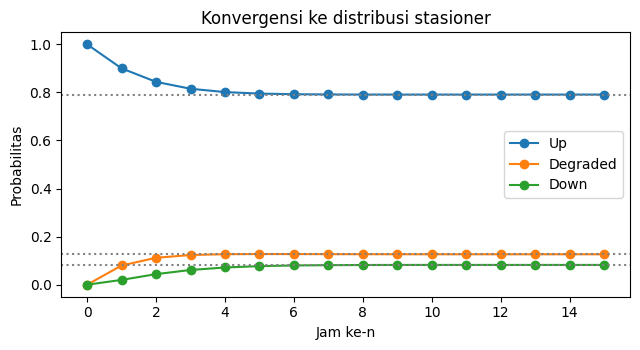

In [12]:
import numpy as np
import matplotlib.pyplot as plt

status = ["Up", "Degraded", "Down"]
P = np.array([[0.90, 0.08, 0.02],
              [0.30, 0.50, 0.20],
              [0.50, 0.00, 0.50]])
pi0 = np.array([1.0, 0.0, 0.0])

for n in [1, 2, 5, 20]:
    pin = pi0 @ np.linalg.matrix_power(P, n)
    print(f"Setelah {n:2d} jam:", dict(zip(status, pin.round(4).tolist())))

# Distribusi stasioner: vektor eigen kiri dengan eigenvalue 1
nilai, vektor = np.linalg.eig(P.T)
idx = np.argmin(abs(nilai - 1))
pi = np.real(vektor[:, idx]); pi = pi / pi.sum()
print("\nDistribusi stasioner:", dict(zip(status, pi.round(4).tolist())))
print("Cek pi·P = pi        :", np.allclose(pi @ P, pi))

# Simulasi satu rantai panjang
rng = np.random.default_rng(9)
T = 200_000
s = 0; hitung = np.zeros(3)
for _ in range(T):
    s = rng.choice(3, p=P[s]); hitung[s] += 1
print("Simulasi proporsi    :", dict(zip(status, (hitung / T).round(4).tolist())))

# Grafik konvergensi
langkah = range(0, 16)
traj = np.array([pi0 @ np.linalg.matrix_power(P, n) for n in langkah])
plt.figure(figsize=(6.5, 3.6))
for j, nm in enumerate(status):
    plt.plot(langkah, traj[:, j], "o-", label=nm); plt.axhline(pi[j], ls=":", color="gray")
plt.xlabel("Jam ke-n"); plt.ylabel("Probabilitas"); plt.title("Konvergensi ke distribusi stasioner")
plt.legend(); plt.tight_layout(); plt.savefig("P11_markov.png", dpi=150); plt.show()

**Coupon Collector: Berapa Percobaan untuk Mendapatkan Semua Jenis?**

H_6 = 2.4500  ->  E[T] teoretis = 14.7000
Simulasi: rata-rata = 14.7194, median = 13.0, std = 6.2761, max = 76
P(T <= 10) simulasi = 0.2720
P(T > 20)  simulasi = 0.1523


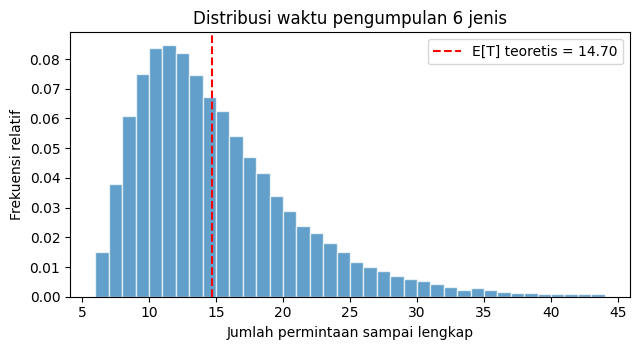

In [13]:
import numpy as np
import matplotlib.pyplot as plt

n = 6
H_n = sum(1 / k for k in range(1, n + 1))
E_teori = n * H_n
print(f"H_{n} = {H_n:.4f}  ->  E[T] teoretis = {E_teori:.4f}")

rng = np.random.default_rng(31)
def satu_percobaan():
    terlihat, t = set(), 0
    while len(terlihat) < n:
        terlihat.add(rng.integers(n)); t += 1
    return t

hasil = np.array([satu_percobaan() for _ in range(50_000)])
print(f"Simulasi: rata-rata = {hasil.mean():.4f}, median = {np.median(hasil)}, "
      f"std = {hasil.std():.4f}, max = {hasil.max()}")
print(f"P(T <= 10) simulasi = {(hasil <= 10).mean():.4f}")
print(f"P(T > 20)  simulasi = {(hasil > 20).mean():.4f}")

plt.figure(figsize=(6.5, 3.6))
plt.hist(hasil, bins=range(6, 45), density=True, alpha=.7, edgecolor="white")
plt.axvline(E_teori, color="red", ls="--", label=f"E[T] teoretis = {E_teori:.2f}")
plt.xlabel("Jumlah permintaan sampai lengkap"); plt.ylabel("Frekuensi relatif")
plt.title("Distribusi waktu pengumpulan 6 jenis"); plt.legend()
plt.tight_layout(); plt.savefig("P12_coupon.png", dpi=150); plt.show()

# Daftar Library Python

**Distribusi Binomial: Pengiriman Paket Jaringan**

P(X=2)  scipy   : 0.2852
P(X=2)  manual  : 0.2852
P(X<=2)         : 0.6769
P(X>=1)         : 0.8784 (= 1 - P(X=0))
E(X), Var(X)    : 2.0 1.8  | rumus np, np(1-p): 2.0 1.8
Simulasi: mean = 1.995 , var = 1.79 , P(X<=2) = 0.6786


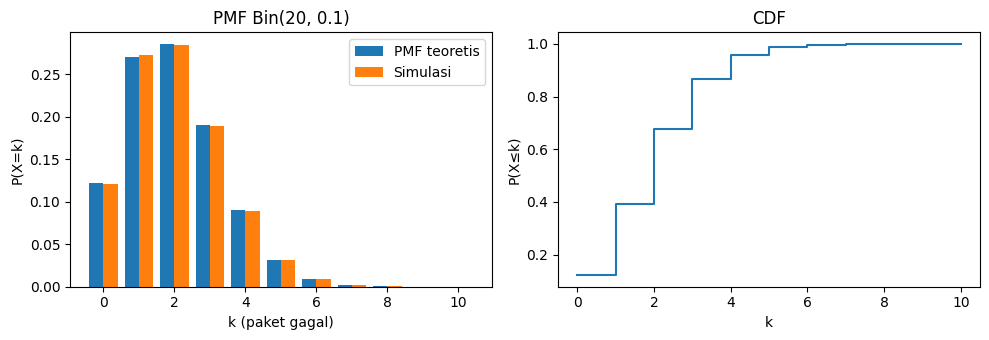

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom
from scipy.special import comb

n, p = 20, 0.10
X = binom(n, p)

print("P(X=2)  scipy   :", round(X.pmf(2), 4))
print("P(X=2)  manual  :", round(comb(n, 2) * p**2 * (1-p)**18, 4))
print("P(X<=2)         :", round(X.cdf(2), 4))
print("P(X>=1)         :", round(1 - X.pmf(0), 4), "(= 1 - P(X=0))")
print("E(X), Var(X)    :", X.mean(), round(X.var(), 2), " | rumus np, np(1-p):", n*p, round(n*p*(1-p), 2))

rng = np.random.default_rng(10)
sampel = rng.binomial(n, p, 200_000)
print("Simulasi: mean =", sampel.mean().round(3), ", var =", sampel.var().round(3),
      ", P(X<=2) =", (sampel <= 2).mean().round(4))

k = np.arange(0, 11)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].bar(k - 0.2, X.pmf(k), 0.4, label="PMF teoretis")
ax[0].bar(k + 0.2, [np.mean(sampel == i) for i in k], 0.4, label="Simulasi")
ax[0].set(title="PMF Bin(20, 0.1)", xlabel="k (paket gagal)", ylabel="P(X=k)"); ax[0].legend()
ax[1].step(k, X.cdf(k), where="post"); ax[1].set(title="CDF", xlabel="k", ylabel="P(X≤k)")
plt.tight_layout(); plt.savefig("D01_binomial.png", dpi=150); plt.show()

**Distribusi Poisson: Kedatangan Request Server**

P(X=6)       : 0.1042
P(X>=10)     : 0.0081 (sf = 1 - cdf)
E, Var       : 4.0 4.0
Kapasitas c : P(X>9) = 0.0081; P(X>8) = 0.0214
-> c minimum agar P(X>c) <= 1% adalah c = 9

Untuk 2.5 detik: E = 10.0 , P(Y<=7) = 0.2202
Simulasi: mean = 4.004 , var = 4.016 , P(X=6) = 0.105


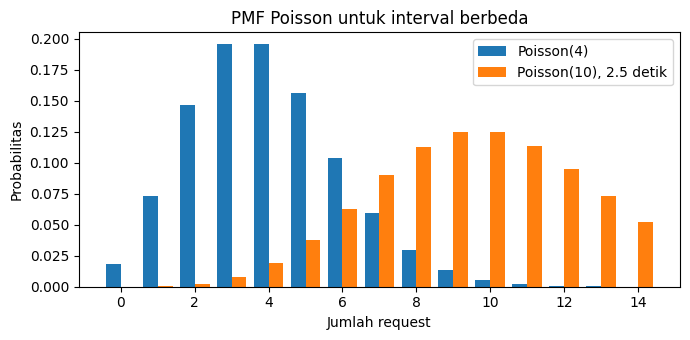

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson

lam = 4
X = poisson(lam)
print("P(X=6)       :", round(X.pmf(6), 4))
print("P(X>=10)     :", round(X.sf(9), 4), "(sf = 1 - cdf)")
print("E, Var       :", X.mean(), X.var())

c = int(X.ppf(0.99))
print(f"Kapasitas c : P(X>{c}) = {X.sf(c):.4f}; P(X>{c-1}) = {X.sf(c-1):.4f}")
print(f"-> c minimum agar P(X>c) <= 1% adalah c = {c if X.sf(c) <= 0.01 else c+1}")

# Interval 2.5 detik -> lambda*t = 10
Y = poisson(lam * 2.5)
print("\nUntuk 2.5 detik: E =", Y.mean(), ", P(Y<=7) =", round(Y.cdf(7), 4))

rng = np.random.default_rng(4)
s = rng.poisson(lam, 300_000)
print("Simulasi: mean =", s.mean().round(3), ", var =", s.var().round(3), ", P(X=6) =", (s == 6).mean().round(4))

k = np.arange(0, 15)
plt.figure(figsize=(7, 3.5))
plt.bar(k - 0.2, X.pmf(k), 0.4, label="Poisson(4)")
plt.bar(k + 0.2, Y.pmf(k), 0.4, label="Poisson(10), 2.5 detik")
plt.xlabel("Jumlah request"); plt.ylabel("Probabilitas"); plt.legend()
plt.title("PMF Poisson untuk interval berbeda"); plt.tight_layout()
plt.savefig("D02_poisson.png", dpi=150); plt.show()

**Distribusi Geometrik dan Binomial Negatif: Percobaan Koneksi**

P(X=3)  : 0.147 | manual (0.7^2)*0.3 = 0.147
P(X<=5) : 0.8319 | manual 1-0.7^5 = 0.8319
E(X), Var(X): 3.3333 7.7778 | 1/p = 3.3333 , (1-p)/p^2 = 7.7778

P(Y=8)  = P(5 gagal sebelum sukses ke-3) : 0.0953
E(Y) = r/p = 10.0 | E(gagal) + r = 10.0
Simulasi geometrik: mean = 3.344 , P(X<=5) = 0.8308
Simulasi neg.binom: mean = 10.002 , P(Y=8) = 0.0962


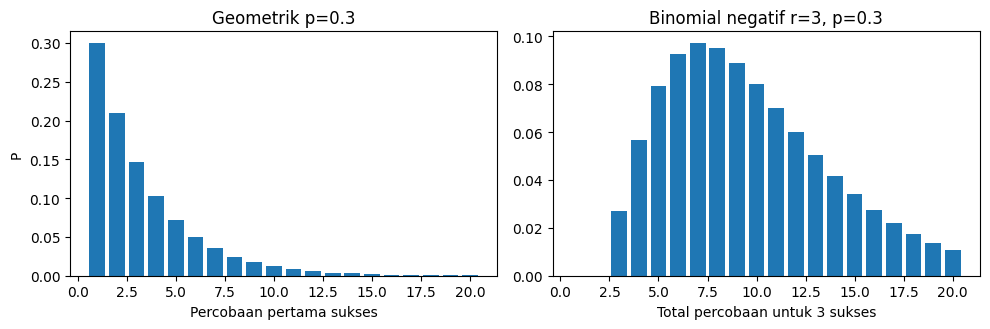

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import geom, nbinom

p = 0.3
G = geom(p)                                    # scipy: k = 1, 2, 3, ...
print("P(X=3)  :", round(G.pmf(3), 4), "| manual (0.7^2)*0.3 =", round(0.7**2 * 0.3, 4))
print("P(X<=5) :", round(G.cdf(5), 4), "| manual 1-0.7^5 =", round(1 - 0.7**5, 4))
print("E(X), Var(X):", round(G.mean(), 4), round(G.var(), 4), "| 1/p =", round(1/p, 4), ", (1-p)/p^2 =", round((1-p)/p**2, 4))

# (b) Binomial negatif: 3 sukses; scipy menghitung jumlah GAGAL
r = 3
NB = nbinom(r, p)
print("\nP(Y=8)  = P(5 gagal sebelum sukses ke-3) :", round(NB.pmf(5), 4))
print("E(Y) = r/p =", round(r / p, 2), "| E(gagal) + r =", round(NB.mean() + r, 2))

rng = np.random.default_rng(21)
sim_g = rng.geometric(p, 200_000)
sim_y = rng.negative_binomial(r, p, 200_000) + r
print("Simulasi geometrik: mean =", sim_g.mean().round(3), ", P(X<=5) =", (sim_g <= 5).mean().round(4))
print("Simulasi neg.binom: mean =", sim_y.mean().round(3), ", P(Y=8) =", (sim_y == 8).mean().round(4))

k = np.arange(1, 21)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].bar(k, G.pmf(k)); ax[0].set(title="Geometrik p=0.3", xlabel="Percobaan pertama sukses", ylabel="P")
ax[1].bar(k, NB.pmf(k - r)); ax[1].set(title="Binomial negatif r=3, p=0.3", xlabel="Total percobaan untuk 3 sukses")
plt.tight_layout(); plt.savefig("D03_geom_nbinom.png", dpi=150); plt.show()

**Distribusi Hipergeometrik: Pengendalian Kualitas Chip**

P(X=2)  scipy  : 0.3217
P(X=2)  manual : 0.3217
P(X>=1)        : 0.8568
E(X)  : 1.6 | nK/M = 1.6
Var(X): 1.0971 | rumus: 1.0971

Perbandingan dengan Binomial(10, 0.16):
  P(X=2) binomial : 0.2856 | Var binomial: 1.344


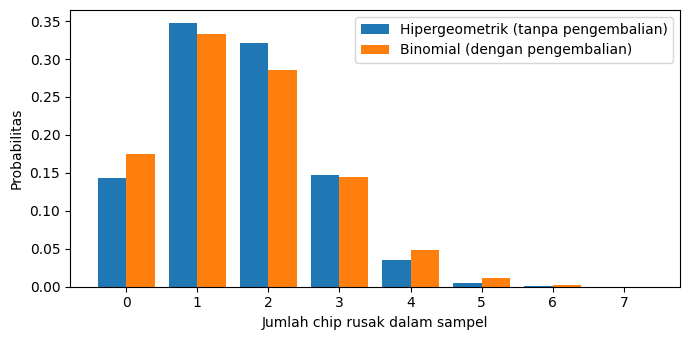

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import hypergeom, binom
from scipy.special import comb

M, K, n = 50, 8, 10          # populasi, rusak, ukuran sampel
H = hypergeom(M, K, n)
print("P(X=2)  scipy  :", round(H.pmf(2), 4))
print("P(X=2)  manual :", round(comb(K, 2) * comb(M-K, n-2) / comb(M, n), 4))
print("P(X>=1)        :", round(H.sf(0), 4))
print("E(X)  :", round(H.mean(), 4), "| nK/M =", n*K/M)
print("Var(X):", round(H.var(), 4), "| rumus:", round(n*(K/M)*(1-K/M)*(M-n)/(M-1), 4))

B = binom(n, K/M)
print("\nPerbandingan dengan Binomial(10, 0.16):")
print("  P(X=2) binomial :", round(B.pmf(2), 4), "| Var binomial:", round(B.var(), 4))

k = np.arange(0, 8)
plt.figure(figsize=(7, 3.5))
plt.bar(k - 0.2, H.pmf(k), 0.4, label="Hipergeometrik (tanpa pengembalian)")
plt.bar(k + 0.2, B.pmf(k), 0.4, label="Binomial (dengan pengembalian)")
plt.xlabel("Jumlah chip rusak dalam sampel"); plt.ylabel("Probabilitas"); plt.legend()
plt.tight_layout(); plt.savefig("D04_hypergeom.png", dpi=150); plt.show()

**Distribusi Multinomial: Klasifikasi Lalu Lintas Jaringan**

In [18]:
import numpy as np
from math import factorial
from scipy.stats import multinomial

p = [0.6, 0.3, 0.1]
n = 10
M = multinomial(n, p)

pmf_scipy = M.pmf([6, 3, 1])
pmf_manual = factorial(10) / (factorial(6) * factorial(3) * factorial(1)) * 0.6**6 * 0.3**3 * 0.1**1
print("P(6,3,1) scipy  :", round(pmf_scipy, 5))
print("P(6,3,1) manual :", round(pmf_manual, 5))

print("\nE[Xi] = n*pi     :", n * np.array(p))
print("Var[Xi]          :", (n * np.array(p) * (1 - np.array(p))).round(2))
print("Cov(HTTP,DNS)    :", round(-n * p[0] * p[1], 2))

rng = np.random.default_rng(8)
s = rng.multinomial(n, p, size=200_000)
print("\nSimulasi mean     :", s.mean(axis=0).round(3))
print("Simulasi P(6,3,1) :", np.mean((s == [6, 3, 1]).all(axis=1)).round(5))
print("Simulasi cov(HTTP,DNS):", np.cov(s[:, 0], s[:, 1])[0, 1].round(3))
print("Korelasi teoretis HTTP-DNS:", round(-np.sqrt(p[0]*p[1]/((1-p[0])*(1-p[1]))), 4))

P(6,3,1) scipy  : 0.10582
P(6,3,1) manual : 0.10582

E[Xi] = n*pi     : [6. 3. 1.]
Var[Xi]          : [2.4 2.1 0.9]
Cov(HTTP,DNS)    : -1.8

Simulasi mean     : [5.999 3.    1.001]
Simulasi P(6,3,1) : 0.10577
Simulasi cov(HTTP,DNS): -1.794
Korelasi teoretis HTTP-DNS: -0.8018


**Aproksimasi Poisson terhadap Binomial: Bug pada Kode**

   Binomial  Poisson  Selisih
0   0.04956  0.04979  0.00022
1   0.14914  0.14936  0.00022
2   0.22415  0.22404  0.00011
3   0.22438  0.22404  0.00034
4   0.16828  0.16803  0.00025
5   0.10087  0.10082  0.00005
6   0.05033  0.05041  0.00008
7   0.02151  0.02160  0.00010
8   0.00803  0.00810  0.00007

Jarak total variasi : 0.000752
P(tidak ada bug)  Bin vs Pois: 0.04956 0.04979
P(>=5 bug)        Bin vs Pois: 0.18448 0.18474

TV distance bila np=3 tetap:
  n=    10, p=0.3000 -> TV = 0.08641
  n=    30, p=0.1000 -> TV = 0.02618
  n=   100, p=0.0300 -> TV = 0.00761
  n=  1000, p=0.0030 -> TV = 0.00075
  n= 10000, p=0.0003 -> TV = 0.00008


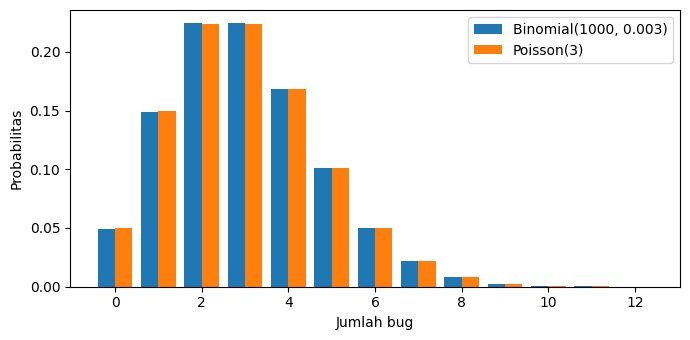

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binom, poisson

n, p = 1000, 0.003
lam = n * p
k = np.arange(0, 13)
tabel = pd.DataFrame({"Binomial": binom.pmf(k, n, p), "Poisson": poisson.pmf(k, lam)}, index=k)
tabel["Selisih"] = (tabel["Binomial"] - tabel["Poisson"]).abs()
print(tabel.round(5).head(9))

k_all = np.arange(0, 60)
tv = 0.5 * np.abs(binom.pmf(k_all, n, p) - poisson.pmf(k_all, lam)).sum()
print("\nJarak total variasi :", round(tv, 6))
print("P(tidak ada bug)  Bin vs Pois:", round(binom.pmf(0, n, p), 5), round(poisson.pmf(0, lam), 5))
print("P(>=5 bug)        Bin vs Pois:", round(binom.sf(4, n, p), 5), round(poisson.sf(4, lam), 5))

# Efek ukuran n dengan np tetap = 3
print("\nTV distance bila np=3 tetap:")
for nn in [10, 30, 100, 1000, 10000]:
    d = 0.5 * np.abs(binom.pmf(k_all, nn, 3/nn) - poisson.pmf(k_all, 3)).sum()
    print(f"  n={nn:6d}, p={3/nn:.4f} -> TV = {d:.5f}")

plt.figure(figsize=(7, 3.5))
plt.bar(k - 0.2, tabel["Binomial"], 0.4, label="Binomial(1000, 0.003)")
plt.bar(k + 0.2, tabel["Poisson"], 0.4, label="Poisson(3)")
plt.xlabel("Jumlah bug"); plt.ylabel("Probabilitas"); plt.legend()
plt.tight_layout(); plt.savefig("D06_poisson_approx.png", dpi=150); plt.show()

**Distribusi Diskrit Kustom: Jumlah Tiket Bug Harian (rv_discrete)**

E(X) = 2.1500, E(X^2) = 6.0500, Var(X) = 1.4275, SD = 1.1948
scipy: mean = 2.1500, var = 1.4275, P(X>=3) = 0.4000
E(C) = 127.50, Var(C) = 3568.75, SD(C) = 59.74
Simulasi: mean(C) = 127.46, var(C) = 3569.65, P(X>=3) = 0.3995


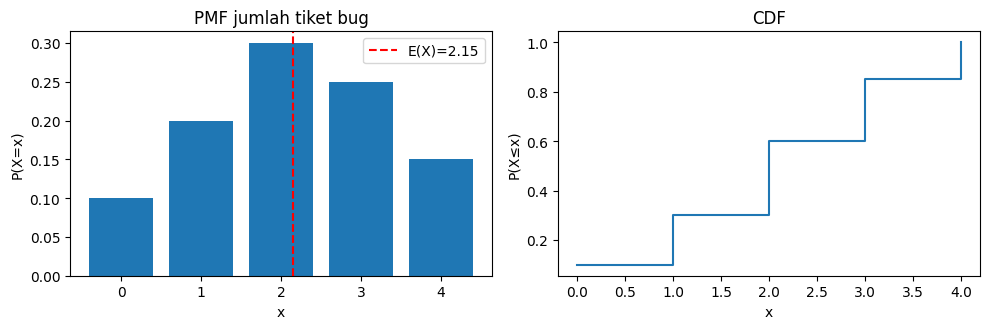

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import rv_discrete

x = np.array([0, 1, 2, 3, 4])
px = np.array([0.10, 0.20, 0.30, 0.25, 0.15])
assert np.isclose(px.sum(), 1.0)

# Perhitungan manual
EX = (x * px).sum()
EX2 = (x**2 * px).sum()
VarX = EX2 - EX**2
print(f"E(X) = {EX:.4f}, E(X^2) = {EX2:.4f}, Var(X) = {VarX:.4f}, SD = {VarX**0.5:.4f}")

# scipy
X = rv_discrete(values=(x, px))
print(f"scipy: mean = {X.mean():.4f}, var = {X.var():.4f}, P(X>=3) = {X.sf(2):.4f}")

# Transformasi linear C = 50X + 20
a, b = 50, 20
print(f"E(C) = {a*EX + b:.2f}, Var(C) = {a**2 * VarX:.2f}, SD(C) = {(a**2 * VarX)**0.5:.2f}")

rng = np.random.default_rng(6)
s = X.rvs(size=500_000, random_state=rng)
C = a * s + b
print(f"Simulasi: mean(C) = {C.mean():.2f}, var(C) = {C.var():.2f}, P(X>=3) = {(s >= 3).mean():.4f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].bar(x, px); ax[0].axvline(EX, color="r", ls="--", label=f"E(X)={EX:.2f}")
ax[0].set(title="PMF jumlah tiket bug", xlabel="x", ylabel="P(X=x)"); ax[0].legend()
ax[1].step(x, X.cdf(x), where="post"); ax[1].set(title="CDF", xlabel="x", ylabel="P(X≤x)")
plt.tight_layout(); plt.savefig("D07_custom_pmf.png", dpi=150); plt.show()

**Distribusi Gabungan (Joint), Marginal, Kondisional, Kovarians, dan Korelasi**

Jumlah seluruh peluang: 1.0

Marginal X: [0.35, 0.45, 0.2]
Marginal Y: [0.32, 0.43, 0.25]

E(X)=0.8500, E(Y)=0.9300, E(XY)=1.0100
Var(X)=0.5275, Var(Y)=0.5651
Cov(X,Y)=0.2195, korelasi rho=0.4020

P(Y | X=1): [0.2222, 0.5556, 0.2222]
E(Y | X=1): 1.0

Apakah X dan Y bebas? P(x,y)==P(x)P(y) untuk semua sel: False
Contoh sel (0,0): P(0,0) = 0.2  vs  P(X=0)P(Y=0) = 0.112


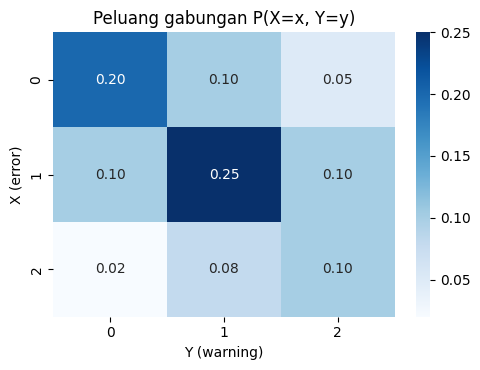

In [21]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Baris = X (error), kolom = Y (warning)
joint = pd.DataFrame([[0.20, 0.10, 0.05],
                      [0.10, 0.25, 0.10],
                      [0.02, 0.08, 0.10]],
                     index=pd.Index([0, 1, 2], name="X (error)"),
                     columns=pd.Index([0, 1, 2], name="Y (warning)"))
print("Jumlah seluruh peluang:", joint.values.sum().round(4))

pX = joint.sum(axis=1)       # marginal X
pY = joint.sum(axis=0)       # marginal Y
print("\nMarginal X:", pX.round(3).tolist())
print("Marginal Y:", pY.round(3).tolist())

x, y = joint.index.values, joint.columns.values
EX, EY = (x * pX).sum(), (y * pY).sum()
EXY = sum(i * j * joint.loc[i, j] for i in x for j in y)
cov = EXY - EX * EY
varX = (x**2 * pX).sum() - EX**2
varY = (y**2 * pY).sum() - EY**2
rho = cov / np.sqrt(varX * varY)
print(f"\nE(X)={EX:.4f}, E(Y)={EY:.4f}, E(XY)={EXY:.4f}")
print(f"Var(X)={varX:.4f}, Var(Y)={varY:.4f}")
print(f"Cov(X,Y)={cov:.4f}, korelasi rho={rho:.4f}")

print("\nP(Y | X=1):", (joint.loc[1] / pX[1]).round(4).tolist())
print("E(Y | X=1):", round(((joint.loc[1] / pX[1]) * y).sum(), 4))

indep = np.allclose(joint.values, np.outer(pX, pY))
print("\nApakah X dan Y bebas? P(x,y)==P(x)P(y) untuk semua sel:", indep)
print("Contoh sel (0,0): P(0,0) =", joint.loc[0, 0], " vs  P(X=0)P(Y=0) =", round(pX[0] * pY[0], 4))

plt.figure(figsize=(5, 3.8))
sns.heatmap(joint, annot=True, fmt=".2f", cmap="Blues")
plt.title("Peluang gabungan P(X=x, Y=y)")
plt.tight_layout(); plt.savefig("D08_joint.png", dpi=150); plt.show()

**Distribusi Uniform Kontinu: Jitter Latensi**

P(X>35)      : 0.375 | manual (50-35)/40 = 0.375
P(20<X<30)   : 0.25
E(X)         : 30.0 | (a+b)/2 = 30.0
Var(X)       : 133.333 | (b-a)^2/12 = 133.333
Median       : 30.0

Inverse transform: mean = 29.998 , var = 133.648 , P(X>35) = 0.3746


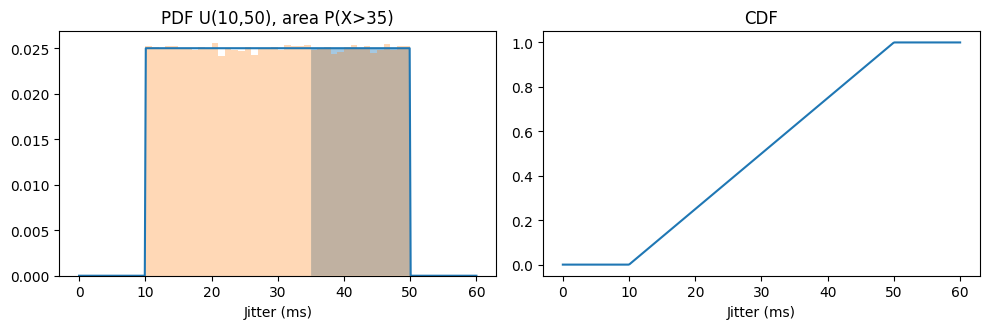

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import uniform

a, b = 10, 50
X = uniform(loc=a, scale=b - a)                 # scipy: loc=a, scale=b-a
print("P(X>35)      :", round(X.sf(35), 4), "| manual (50-35)/40 =", 15 / 40)
print("P(20<X<30)   :", round(X.cdf(30) - X.cdf(20), 4))
print("E(X)         :", X.mean(), "| (a+b)/2 =", (a + b) / 2)
print("Var(X)       :", round(X.var(), 3), "| (b-a)^2/12 =", round((b - a)**2 / 12, 3))
print("Median       :", X.median())

# Inverse transform sampling
rng = np.random.default_rng(15)
u = rng.random(200_000)
x_inv = a + (b - a) * u                           # F^{-1}(u) = a + (b-a)u
print("\nInverse transform: mean =", x_inv.mean().round(3), ", var =", x_inv.var().round(3),
      ", P(X>35) =", (x_inv > 35).mean().round(4))

xs = np.linspace(0, 60, 400)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(xs, X.pdf(xs)); ax[0].fill_between(xs, X.pdf(xs), where=xs > 35, alpha=.4)
ax[0].hist(x_inv, bins=40, density=True, alpha=.3)
ax[0].set(title="PDF U(10,50), area P(X>35)", xlabel="Jitter (ms)")
ax[1].plot(xs, X.cdf(xs)); ax[1].set(title="CDF", xlabel="Jitter (ms)")
plt.tight_layout(); plt.savefig("D09_uniform.png", dpi=150); plt.show()

**Distribusi Eksponensial: Waktu Antar Kegagalan dan Sifat Memoryless**

P(T>600)      : 0.3012 | e^(-600/500) = 0.3012
P(T<=250)     : 0.3935
E(T), Var(T)  : 500.0 250000.0 | SD = 500.0
Median        : 346.57 | 500*ln2 = 346.57
Persentil 90  : 1151.29 jam

P(T>800 | T>200) = 0.3012   vs   P(T>600) = 0.3012
Simulasi: P(T>600) = 0.3007, P(T>800|T>200) = 0.3005


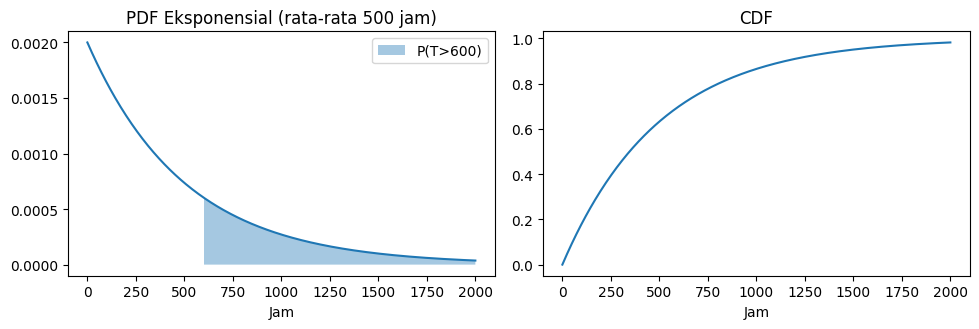

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import expon

mean_T = 500
lam = 1 / mean_T
T = expon(scale=mean_T)                         # scipy memakai scale = 1/lambda

print("P(T>600)      :", round(T.sf(600), 4), "| e^(-600/500) =", round(np.exp(-1.2), 4))
print("P(T<=250)     :", round(T.cdf(250), 4))
print("E(T), Var(T)  :", T.mean(), T.var(), "| SD =", T.std())
print("Median        :", round(T.median(), 2), "| 500*ln2 =", round(500 * np.log(2), 2))
print("Persentil 90  :", round(T.ppf(0.9), 2), "jam")

# Sifat memoryless
kiri = T.sf(800) / T.sf(200)
print(f"\nP(T>800 | T>200) = {kiri:.4f}   vs   P(T>600) = {T.sf(600):.4f}")

rng = np.random.default_rng(12)
s = rng.exponential(mean_T, 1_000_000)
lewat200 = s[s > 200]
print(f"Simulasi: P(T>600) = {(s > 600).mean():.4f}, P(T>800|T>200) = {(lewat200 > 800).mean():.4f}")

t = np.linspace(0, 2000, 500)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(t, T.pdf(t)); ax[0].fill_between(t, T.pdf(t), where=t > 600, alpha=.4, label="P(T>600)")
ax[0].set(title="PDF Eksponensial (rata-rata 500 jam)", xlabel="Jam"); ax[0].legend()
ax[1].plot(t, T.cdf(t)); ax[1].set(title="CDF", xlabel="Jam")
plt.tight_layout(); plt.savefig("D10_exponential.png", dpi=150); plt.show()

**Distribusi Normal: Waktu Respons API**

z untuk 250 ms = 1.667
P(X>250)      : 0.0478 | via Z: 0.0478
P(170<X<230)  : 0.6827
Persentil 95  : 249.35 ms  | mu + 1.645*sigma = 249.35
Persentil 99  : 269.79 ms
P(|X-mu|<1sigma) = 0.6827
P(|X-mu|<2sigma) = 0.9545
P(|X-mu|<3sigma) = 0.9973

Sampel 500: mean = 198.68 , sd = 29.9 , P(>250) = 0.038
Uji Shapiro-Wilk: W = 0.9965, p = 0.3355 -> normal tidak ditolak


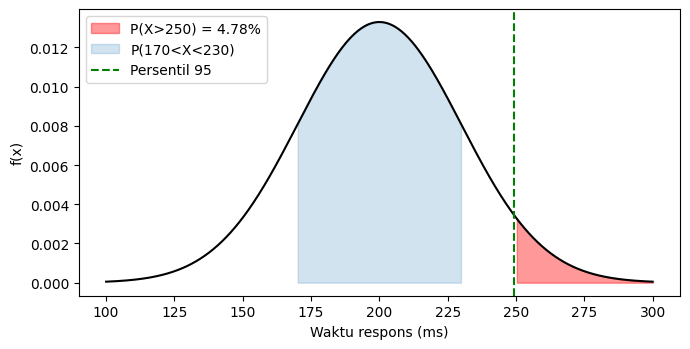

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, shapiro

mu, sigma = 200, 30
X = norm(mu, sigma)

z250 = (250 - mu) / sigma
print(f"z untuk 250 ms = {z250:.3f}")
print("P(X>250)      :", round(X.sf(250), 4), "| via Z:", round(norm.sf(z250), 4))
print("P(170<X<230)  :", round(X.cdf(230) - X.cdf(170), 4))
print("Persentil 95  :", round(X.ppf(0.95), 2), "ms  | mu + 1.645*sigma =", round(mu + 1.645 * sigma, 2))
print("Persentil 99  :", round(X.ppf(0.99), 2), "ms")

for k in [1, 2, 3]:
    print(f"P(|X-mu|<{k}sigma) = {X.cdf(mu + k*sigma) - X.cdf(mu - k*sigma):.4f}")

rng = np.random.default_rng(17)
s = X.rvs(500, random_state=rng)
print("\nSampel 500: mean =", s.mean().round(2), ", sd =", s.std(ddof=1).round(2),
      ", P(>250) =", (s > 250).mean().round(4))
stat, pval = shapiro(s)
print(f"Uji Shapiro-Wilk: W = {stat:.4f}, p = {pval:.4f} ->", "normal tidak ditolak" if pval > 0.05 else "ditolak")

xs = np.linspace(100, 300, 500)
plt.figure(figsize=(7, 3.6))
plt.plot(xs, X.pdf(xs), "k")
plt.fill_between(xs, X.pdf(xs), where=xs > 250, color="red", alpha=.4, label="P(X>250) = 4.78%")
plt.fill_between(xs, X.pdf(xs), where=(xs > 170) & (xs < 230), color="tab:blue", alpha=.2, label="P(170<X<230)")
plt.axvline(X.ppf(0.95), color="green", ls="--", label="Persentil 95")
plt.xlabel("Waktu respons (ms)"); plt.ylabel("f(x)"); plt.legend()
plt.tight_layout(); plt.savefig("D11_normal.png", dpi=150); plt.show()

**Teorema Limit Pusat dan Aproksimasi Normal terhadap Binomial**

n= 1: mean = 1.984 (teori 2.000), sd = 1.991 (teori 2.000), skewness = 2.041
n= 2: mean = 2.009 (teori 2.000), sd = 1.415 (teori 1.414), skewness = 1.368
n= 5: mean = 2.000 (teori 2.000), sd = 0.895 (teori 0.894), skewness = 0.892
n=30: mean = 2.000 (teori 2.000), sd = 0.366 (teori 0.365), skewness = 0.359


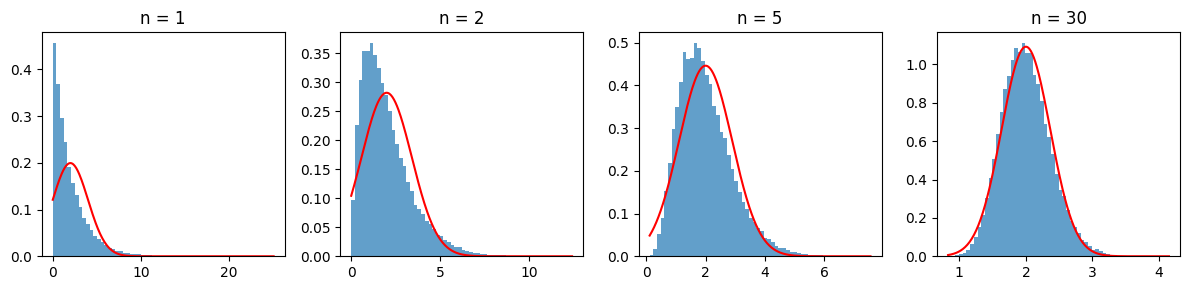


P(X<=55) eksak (binomial)      : 0.8644
Aproksimasi normal tanpa koreksi : 0.8413
Aproksimasi normal + koreksi 0.5 : 0.8643


In [25]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, binom, skew

rng = np.random.default_rng(100)
mean_exp = 2.0
fig, ax = plt.subplots(1, 4, figsize=(12, 3), sharey=False)
for a, n in zip(ax, [1, 2, 5, 30]):
    rata = rng.exponential(mean_exp, (50_000, n)).mean(axis=1)
    a.hist(rata, bins=60, density=True, alpha=.7)
    xs = np.linspace(rata.min(), rata.max(), 300)
    a.plot(xs, norm.pdf(xs, mean_exp, mean_exp / np.sqrt(n)), "r")
    a.set_title(f"n = {n}")
    print(f"n={n:2d}: mean = {rata.mean():.3f} (teori 2.000), sd = {rata.std():.3f} "
          f"(teori {mean_exp/np.sqrt(n):.3f}), skewness = {skew(rata):.3f}")
plt.tight_layout(); plt.savefig("D12_clt.png", dpi=150); plt.show()

# (b) Aproksimasi normal terhadap binomial
n, p, k = 100, 0.5, 55
mu, sd = n * p, np.sqrt(n * p * (1 - p))
print("\nP(X<=55) eksak (binomial)      :", round(binom.cdf(k, n, p), 4))
print("Aproksimasi normal tanpa koreksi :", round(norm.cdf(k, mu, sd), 4))
print("Aproksimasi normal + koreksi 0.5 :", round(norm.cdf(k + 0.5, mu, sd), 4))

**Distribusi Gamma (Erlang): Waktu Hingga r Kejadian**

E(T)  : 1.5 | r/lambda = 1.5
Var(T): 0.75 | r/lambda^2 = 0.75
P(T<=2) gamma  : 0.7619
P(N(2)>=3) Poisson(4): 0.7619
Simulasi: mean = 1.5013 , var = 0.753 , P(T<=2) = 0.7617


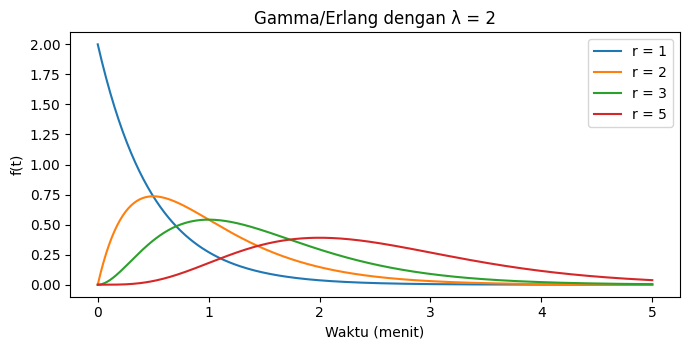

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gamma, poisson

lam, r = 2, 3
T = gamma(a=r, scale=1 / lam)
print("E(T)  :", T.mean(), "| r/lambda =", r / lam)
print("Var(T):", T.var(), "| r/lambda^2 =", r / lam**2)
print("P(T<=2) gamma  :", round(T.cdf(2), 4))
print("P(N(2)>=3) Poisson(4):", round(poisson.sf(2, lam * 2), 4))

rng = np.random.default_rng(55)
# Jumlahkan 3 waktu antar-kedatangan eksponensial
s = rng.exponential(1 / lam, (300_000, r)).sum(axis=1)
print("Simulasi: mean =", s.mean().round(4), ", var =", s.var().round(4), ", P(T<=2) =", (s <= 2).mean().round(4))

t = np.linspace(0, 5, 400)
plt.figure(figsize=(7, 3.6))
for rr in [1, 2, 3, 5]:
    plt.plot(t, gamma(a=rr, scale=1 / lam).pdf(t), label=f"r = {rr}")
plt.xlabel("Waktu (menit)"); plt.ylabel("f(t)"); plt.title("Gamma/Erlang dengan λ = 2"); plt.legend()
plt.tight_layout(); plt.savefig("D13_gamma.png", dpi=150); plt.show()

**Distribusi Weibull: Umur Hard Disk dan Laju Kegagalan**

P(T<=500)    : 0.2978 | 1-exp(-0.5^1.5) = 0.2978
P(T>1500)    : 0.1593
E(T)         : 902.75 | lam*Gamma(1+1/k) = 902.75
Median       : 783.22
SD           : 612.94
Simulasi: mean = 903.06 , P(T<=500) = 0.2975


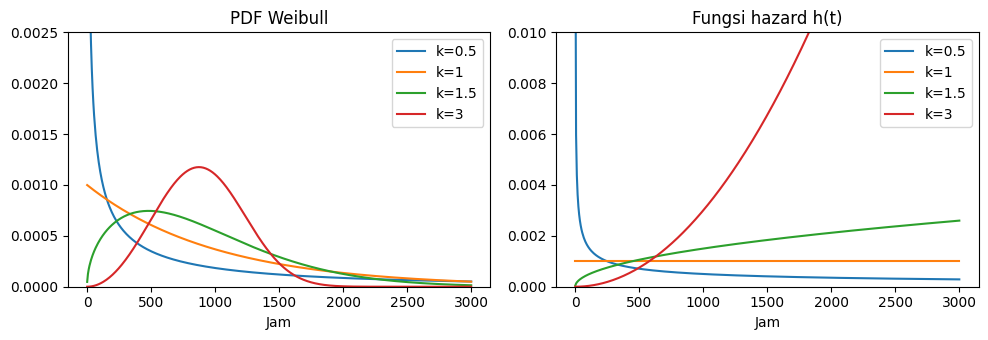

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import weibull_min
from scipy.special import gamma as G

k, lam = 1.5, 1000
T = weibull_min(c=k, scale=lam)
print("P(T<=500)    :", round(T.cdf(500), 4), "| 1-exp(-0.5^1.5) =", round(1 - np.exp(-(0.5)**1.5), 4))
print("P(T>1500)    :", round(T.sf(1500), 4))
print("E(T)         :", round(T.mean(), 2), "| lam*Gamma(1+1/k) =", round(lam * G(1 + 1/k), 2))
print("Median       :", round(T.median(), 2))
print("SD           :", round(T.std(), 2))

rng = np.random.default_rng(77)
s = lam * rng.weibull(k, 500_000)
print("Simulasi: mean =", s.mean().round(2), ", P(T<=500) =", (s <= 500).mean().round(4))

# Fungsi hazard
t = np.linspace(1, 3000, 500)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for kk in [0.5, 1, 1.5, 3]:
    W = weibull_min(c=kk, scale=lam)
    ax[0].plot(t, W.pdf(t), label=f"k={kk}")
    ax[1].plot(t, W.pdf(t) / W.sf(t), label=f"k={kk}")
ax[0].set(title="PDF Weibull", xlabel="Jam", ylim=(0, 0.0025)); ax[0].legend()
ax[1].set(title="Fungsi hazard h(t)", xlabel="Jam", ylim=(0, 0.01)); ax[1].legend()
plt.tight_layout(); plt.savefig("D14_weibull.png", dpi=150); plt.show()

**Distribusi Beta: Inferensi Bayesian pada A/B Testing**

Desain A: posterior Beta(31, 71) | mean = 0.3039 | 95% CI = (0.2190, 0.3961)
Desain B: posterior Beta(46, 76) | mean = 0.3770 | 95% CI = (0.2935, 0.4644)

P(pB > pA)            = 0.8768
P(pB > pA + 0.05)     = 0.6453
Perbedaan rata-rata   = 0.0731
CI 95% untuk (pB-pA)  = [-0.0512  0.1955]


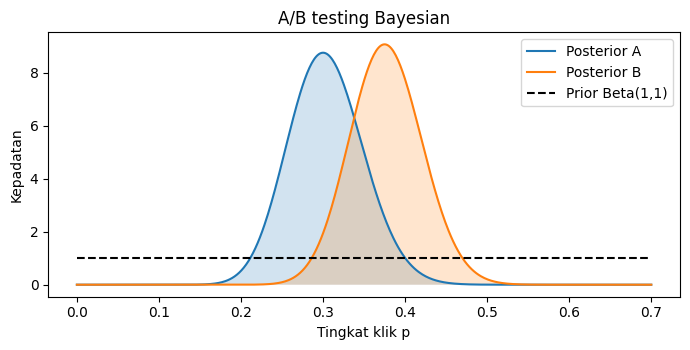

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta

a0, b0 = 1, 1                                   # prior seragam
data = {"A": (30, 100), "B": (45, 120)}
post = {}
for nm, (s, n) in data.items():
    post[nm] = beta(a0 + s, b0 + n - s)
    lo, hi = post[nm].interval(0.95)
    print(f"Desain {nm}: posterior Beta({a0+s}, {b0+n-s}) | mean = {post[nm].mean():.4f} | "
          f"95% CI = ({lo:.4f}, {hi:.4f})")

rng = np.random.default_rng(2)
pA = post["A"].rvs(500_000, random_state=rng)
pB = post["B"].rvs(500_000, random_state=rng)
print(f"\nP(pB > pA)            = {(pB > pA).mean():.4f}")
print(f"P(pB > pA + 0.05)     = {(pB > pA + 0.05).mean():.4f}")
print(f"Perbedaan rata-rata   = {(pB - pA).mean():.4f}")
print(f"CI 95% untuk (pB-pA)  = {np.percentile(pB - pA, [2.5, 97.5]).round(4)}")

x = np.linspace(0, 0.7, 500)
plt.figure(figsize=(7, 3.6))
for nm in post:
    plt.plot(x, post[nm].pdf(x), label=f"Posterior {nm}")
    plt.fill_between(x, post[nm].pdf(x), alpha=.2)
plt.plot(x, beta(a0, b0).pdf(x), "k--", label="Prior Beta(1,1)")
plt.xlabel("Tingkat klik p"); plt.ylabel("Kepadatan"); plt.legend(); plt.title("A/B testing Bayesian")
plt.tight_layout(); plt.savefig("D15_beta.png", dpi=150); plt.show()

**Distribusi t-Student dan Chi-Kuadrat: Selang Kepercayaan**

n = 15, mean = 106.133, s = 7.909
t kritis (df=14) = 2.1448
CI 95% (t) manual : [101.753 110.513]
CI 95% (t) scipy  : [101.753 110.513]
CI 95% (z) -> terlalu sempit: [102.131 110.136]

CI 95% variansi : (33.53, 155.58)  ->  simpangan baku (5.79, 12.47)

Uji t H0: mu=100 -> t = 3.003, p-value = 0.0095
Keputusan (alpha=5%): Tolak H0


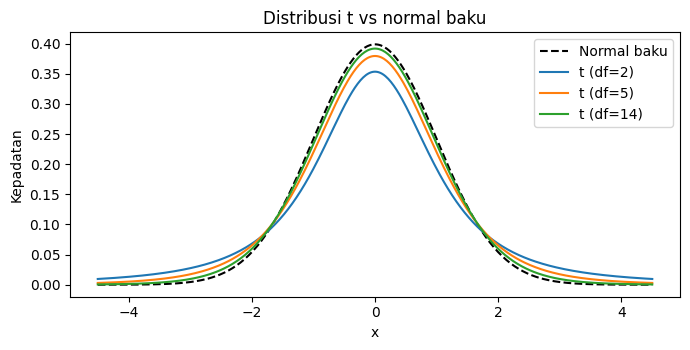

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import t, chi2, norm, ttest_1samp

data = np.array([112, 98, 105, 120, 101, 95, 110, 108, 99, 117, 103, 106, 115, 94, 109])
n = len(data); xbar = data.mean(); s = data.std(ddof=1)
print(f"n = {n}, mean = {xbar:.3f}, s = {s:.3f}")

# CI rata-rata (t) dan perbandingan dengan normal
t_crit = t.ppf(0.975, df=n - 1)
ci_t = (xbar - t_crit * s / np.sqrt(n), xbar + t_crit * s / np.sqrt(n))
ci_scipy = t.interval(0.95, df=n - 1, loc=xbar, scale=s / np.sqrt(n))
ci_z = norm.interval(0.95, loc=xbar, scale=s / np.sqrt(n))
print(f"t kritis (df=14) = {t_crit:.4f}")
print("CI 95% (t) manual :", np.round(ci_t, 3))
print("CI 95% (t) scipy  :", np.round(ci_scipy, 3))
print("CI 95% (z) -> terlalu sempit:", np.round(ci_z, 3))

# CI variansi (chi-kuadrat)
lo = (n - 1) * s**2 / chi2.ppf(0.975, n - 1)
hi = (n - 1) * s**2 / chi2.ppf(0.025, n - 1)
print(f"\nCI 95% variansi : ({lo:.2f}, {hi:.2f})  ->  simpangan baku ({np.sqrt(lo):.2f}, {np.sqrt(hi):.2f})")

# Uji t satu sampel
stat, pval = ttest_1samp(data, popmean=100)
print(f"\nUji t H0: mu=100 -> t = {stat:.3f}, p-value = {pval:.4f}")
print("Keputusan (alpha=5%):", "Tolak H0" if pval < 0.05 else "Gagal menolak H0")

xs = np.linspace(-4.5, 4.5, 400)
plt.figure(figsize=(7, 3.6))
plt.plot(xs, norm.pdf(xs), "k--", label="Normal baku")
for df in [2, 5, 14]:
    plt.plot(xs, t.pdf(xs, df), label=f"t (df={df})")
plt.xlabel("x"); plt.ylabel("Kepadatan"); plt.legend(); plt.title("Distribusi t vs normal baku")
plt.tight_layout(); plt.savefig("D16_t_chi2.png", dpi=150); plt.show()

**Fitting Distribusi pada Data dan Uji Kecocokan (Goodness of Fit)**

Data: n=200, mean=157.9, median=143.6, min=67.7, max=471.6

               LogLik        AIC  KS stat  KS p-value
Distribusi                                           
Normal     -1110.1129  2224.2259   0.1097      0.0150
Gamma      -1083.9607  2171.9215   0.0626      0.3977
Log-normal -1077.7570  2159.5141   0.0394      0.9033

Model terbaik (AIC terkecil): Log-normal
Parameter log-normal: s = 0.3588 , scale = exp(mu) = 147.63 (sebenarnya sigma=0.4, exp(5)=148.41)


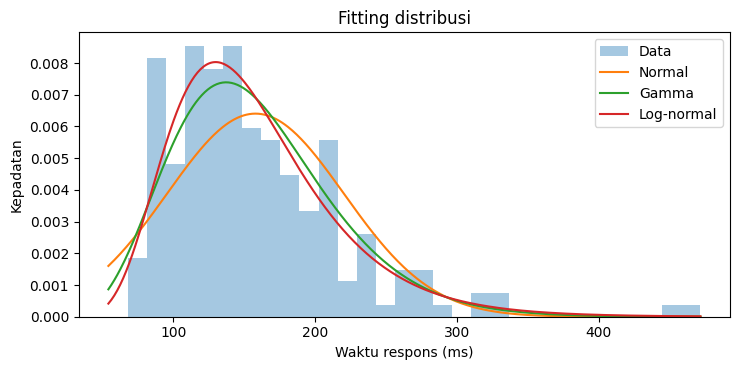

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, gamma, lognorm, kstest

rng = np.random.default_rng(88)
data = rng.lognormal(mean=5.0, sigma=0.4, size=200)           # data "pengamatan"
print(f"Data: n={len(data)}, mean={data.mean():.1f}, median={np.median(data):.1f}, "
      f"min={data.min():.1f}, max={data.max():.1f}")

kandidat = {"Normal": norm, "Gamma": gamma, "Log-normal": lognorm}
baris, param_fit = [], {}
for nama, dist in kandidat.items():
    if nama == "Normal":
        par = dist.fit(data)
    else:
        par = dist.fit(data, floc=0)               # batas bawah dipatok 0 untuk data positif
    param_fit[nama] = par
    ll = dist.logpdf(data, *par).sum()
    k = len(par) - (0 if nama == "Normal" else 1)  # loc dipatok tidak dihitung sbg parameter
    ks = kstest(data, dist.cdf, args=par)
    baris.append([nama, ll, 2 * k - 2 * ll, ks.statistic, ks.pvalue])

hasil = pd.DataFrame(baris, columns=["Distribusi", "LogLik", "AIC", "KS stat", "KS p-value"]).set_index("Distribusi")
print()
print(hasil.round(4))
print("\nModel terbaik (AIC terkecil):", hasil["AIC"].idxmin())
print("Parameter log-normal: s =", round(param_fit["Log-normal"][0], 4),
      ", scale = exp(mu) =", round(param_fit["Log-normal"][2], 2),
      "(sebenarnya sigma=0.4, exp(5)=148.41)")

xs = np.linspace(data.min() * 0.8, data.max(), 400)
plt.figure(figsize=(7.5, 3.8))
plt.hist(data, bins=30, density=True, alpha=.4, label="Data")
for nama, dist in kandidat.items():
    plt.plot(xs, dist.pdf(xs, *param_fit[nama]), label=nama)
plt.xlabel("Waktu respons (ms)"); plt.ylabel("Kepadatan"); plt.legend(); plt.title("Fitting distribusi")
plt.tight_layout(); plt.savefig("D17_fitting.png", dpi=150); plt.show()